# Chapter 4: Nearness

Checks [chapter 4](../../book/04-nearness.md) on the sine, where everything is exact.
A model covers a label range within `reach` when, from any input, some input no further than
`reach` away is sent exactly to any chosen label. For `amplitude * sin(frequency * input + phase)`
the inputs that hit a label are known in closed form, so the reach is computed, not estimated:

    inputs that hit label = (asin(label / amplitude) - phase + 2 pi k) / frequency
                            (pi - asin(label / amplitude) - phase + 2 pi k) / frequency

`get_nearest_hit` in `common.py` picks the nearest of these. These are measurements of the sine
case. The Lean theorems cover any model that covers its labels.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import pandas as pd

from common import *

use_style()
generator = torch.Generator().manual_seed(4)

## What is a warp?

A **warp** is a way to move each input a little. Take a model and a target function. At each
input, ask which label the target wants there. If the model covers its labels within `reach`,
some input no further than `reach` away is sent by the model exactly to that label. The warp
sends each input to that nearby input. Then the model, read at the moved input, equals the
target, at every input at once.

So a warp does not change the model. It changes where you read it, and `reach` bounds how far
you move. A squigglier model has a smaller reach, so it needs a smaller move.

## Claim: a sine covers its band within pi over its frequency

Chapter 4, the example. `sin(x)` covers the band from -1 to 1 within `pi`, `sin(8x)` within
`pi / 8`, and `sin(20x)` within `pi / 20`. For each frequency, take a grid of inputs over one
period and a grid of labels over the band, find the nearest input that hits each label, and
take the largest distance needed. That is the measured reach.

In [2]:
reach_rows = []

for frequency in (1.0, 8.0, 20.0):
    phase = 0.0
    amplitude = 1.0
    grid_inputs = torch.linspace(0, TWO_PI / frequency, 801)
    grid_labels = torch.linspace(-amplitude, amplitude, 801)
    inputs = grid_inputs.repeat_interleave(len(grid_labels))
    labels = grid_labels.repeat(len(grid_inputs))

    hits = get_nearest_hit(amplitude, frequency, phase, inputs, labels)
    largest_shift = float((hits - inputs).abs().max())
    hit_error = float((evaluate_sine(amplitude, frequency, phase, hits) - labels).abs().max())
    reach_rows.append({"frequency": frequency, "measured_reach": largest_shift,
                       "pi_over_frequency": math.pi / frequency, "hit_error": hit_error})

    report(f"sin({frequency:g} x) needs a reach of exactly pi / {frequency:g} = {math.pi / frequency:.4f}",
           abs(largest_shift - math.pi / frequency) < 1e-6 and hit_error < 1e-9,
           f"largest shift needed {largest_shift:.4f}")

[PASS] sin(1 x) needs a reach of exactly pi / 1 = 3.1416  (largest shift needed 3.1416)
[PASS] sin(8 x) needs a reach of exactly pi / 8 = 0.3927  (largest shift needed 0.3927)
[PASS] sin(20 x) needs a reach of exactly pi / 20 = 0.1571  (largest shift needed 0.1571)


## Claim 2: a small shift of the inputs fits any target

Take a target whose values stay in the band, `0.8 cos(1.7 x) sin(0.4 x + 1)`, on 20,000 random
inputs. The warp sends each input to the nearest input where the sine `0.8 sin(frequency * x + 1.3)`
equals the target there. The check is that no input moves more than `pi / frequency` and that the
model read at the moved input matches the target to rounding error. The cell also keeps the
mean gap to the target before the warp, for the figure below.

In [3]:
amplitude, phase = 0.8, 1.3
warp_frequencies = (2.0, 8.0, 20.0)
warp_rows = []

for frequency in warp_frequencies:
    inputs = torch.rand(20000, generator=generator) * 10 - 5
    target = 0.8 * torch.cos(1.7 * inputs) * torch.sin(0.4 * inputs + 1)     # stays inside the band

    warp = get_nearest_hit(amplitude, frequency, phase, inputs, target)
    largest_shift = float((warp - inputs).abs().max())
    fit_error = float((evaluate_sine(amplitude, frequency, phase, warp) - target).abs().max())
    gap_before = float((evaluate_sine(amplitude, frequency, phase, inputs) - target).abs().mean())
    warp_rows.append({"frequency": frequency, "largest_shift": largest_shift, "pi_over_frequency": math.pi / frequency,
                      "fit_error": fit_error, "gap_before": gap_before})

    report(f"warp at frequency {frequency:g}: shift <= pi / frequency and the fit is exact",
           largest_shift <= math.pi / frequency + 1e-9 and fit_error < 1e-9,
           f"shift {largest_shift:.4f} of {math.pi / frequency:.4f}, fit error {fit_error:.1e}")

[PASS] warp at frequency 2: shift <= pi / frequency and the fit is exact  (shift 0.8242 of 1.5708, fit error 1.5e-15)
[PASS] warp at frequency 8: shift <= pi / frequency and the fit is exact  (shift 0.3402 of 0.3927, fit error 6.4e-15)
[PASS] warp at frequency 20: shift <= pi / frequency and the fit is exact  (shift 0.1464 of 0.1571, fit error 1.8e-14)


## Claim 3: the slope tax

Chapter 3 says the vertical error is at most `sqrt(1 + slope_limit^2)` times the nearest distance, and the
covering bound says the nearest distance is at most `reach`. Together the vertical error is at most
`sqrt(1 + slope_limit^2) * reach`. For a sine of amplitude 1 and labels in the band the second form is
built in (the vertical error is at most 2 and the budget is at least `pi`), so the check that can fail is
the first, against the *measured* nearest distance, which is much smaller than the reach. The nearest
distance is measured with `include_foot=False`. Thirty random data points at each of three frequencies.
The budget check is kept and printed, and labelled as the consequence.


In [4]:
largest_vertical_over_tax = 0.0
largest_vertical_over_budget = 0.0
nearest_within_reach = True

for frequency in (2.0, 6.0, 15.0):
    amplitude = 1.0
    phase = float(torch.rand(1, generator=generator)) * TWO_PI
    curve = lambda inputs, a=amplitude, w=frequency, p=phase: evaluate_sine(a, w, p, inputs)
    slope_limit = amplitude * frequency
    reach = math.pi / frequency

    for _ in range(30):
        point_x = float(torch.rand(1, generator=generator)) * 2 - 1
        point_y = float(torch.rand(1, generator=generator)) * 2 * amplitude - amplitude
        vertical_error = abs(point_y - float(curve(torch.tensor([point_x]))))
        nearest_distance = get_nearest_distance(curve, point_x, point_y, slope_limit, resolution=2e-3,
                                                include_foot=False)
        tax = math.sqrt(1 + slope_limit ** 2)
        largest_vertical_over_tax = max(largest_vertical_over_tax, vertical_error / (tax * nearest_distance))
        largest_vertical_over_budget = max(largest_vertical_over_budget, vertical_error / (tax * reach))
        nearest_within_reach &= nearest_distance <= reach + 1e-9

report("the nearest distance is within reach at every data point", nearest_within_reach)
report("slope tax: vertical error <= sqrt(1 + slope_limit^2) * the measured nearest distance",
       largest_vertical_over_tax <= 1.0 + 3e-4,
       f"largest vertical / (tax * nearest) = {largest_vertical_over_tax:.3f}")
report("consequence: vertical error <= sqrt(1 + slope_limit^2) * reach (built in for a sine)",
       largest_vertical_over_budget <= 1.0, f"largest vertical / budget = {largest_vertical_over_budget:.3f}")


[PASS] the nearest distance is within reach at every data point
[PASS] slope tax: vertical error <= sqrt(1 + slope_limit^2) * the measured nearest distance  (largest vertical / (tax * nearest) = 0.997)
[PASS] consequence: vertical error <= sqrt(1 + slope_limit^2) * reach (built in for a sine)  (largest vertical / budget = 0.545)


True

## Check yourself

Question 1: `sin(20x)` needs reach `pi / 20`, about 0.157. Question 2: with reach 0.01 and slope
at most 2, the vertical error is at most `sqrt(5) * 0.01`, about 0.0224. Both are measured below.


In [5]:
check_inputs = torch.linspace(0, TWO_PI / 20, 801).repeat_interleave(801)
check_labels = torch.linspace(-1, 1, 801).repeat(801)
check_hits = get_nearest_hit(1.0, 20.0, 0.0, check_inputs, check_labels)
check_reach = float((check_hits - check_inputs).abs().max())
report("sin(20 x) needs reach pi / 20 = 0.157", abs(check_reach - 0.157) < 1e-3, f"measured {check_reach:.4f}")

# A line of slope 2 and a point 0.01 from it along its normal: the vertical error is sqrt(5) * 0.01.
normal_step = 0.01 / math.sqrt(5)
check_x, check_y = -2 * normal_step, normal_step
line_of_slope_two = lambda inputs: 2.0 * inputs
two_nearest = get_nearest_distance(line_of_slope_two, check_x, check_y, 2.0, resolution=1e-5, include_foot=False)
two_vertical = get_vertical_error(line_of_slope_two(torch.tensor(check_x)), check_y)
report("reach 0.01, slope 2: the vertical error reaches sqrt(5) * 0.01 = 0.0224 and no more",
       abs(two_nearest - 0.01) < 1e-6 and abs(two_vertical - math.sqrt(5) * 0.01) < 1e-6,
       f"nearest {two_nearest:.5f}, vertical {two_vertical:.5f}")


[PASS] sin(20 x) needs reach pi / 20 = 0.157  (measured 0.1571)


[PASS] reach 0.01, slope 2: the vertical error reaches sqrt(5) * 0.01 = 0.0224 and no more  (nearest 0.01000, vertical 0.02236)


True

## Figure: covering within reach

Written to `book/figures/04-covers-within-reach.png`. Two sines and the label 0.55. The purple dots
are every input that hits the label. From the black input, which sits on the label line, the shaded window of half-width `reach`
always holds one, and the arrow runs to the nearest.

wrote book/figures/04-covers-within-reach.png


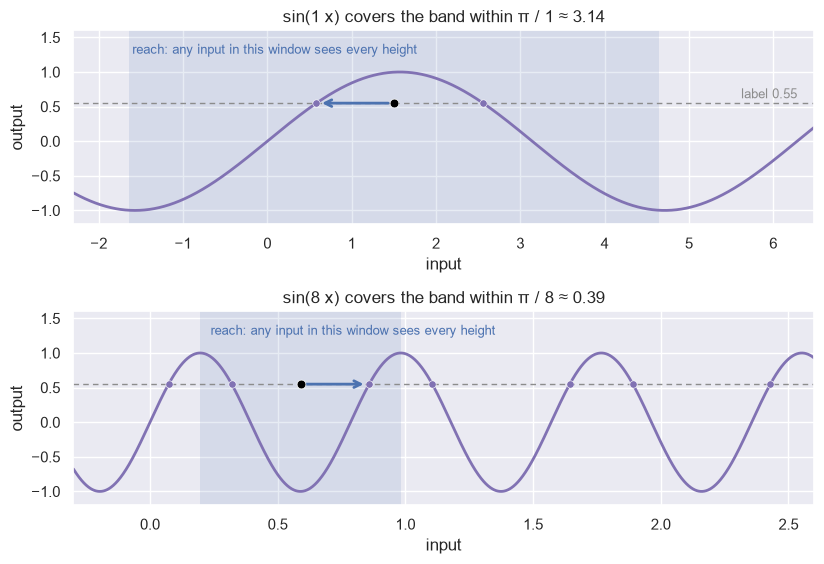

In [6]:
label = 0.55
xs = np.linspace(-2.3, 2 * math.pi + 0.2, 6000)
starts = {1.0: 1.5, 8.0: 0.59}           # chosen so that the arrow has a visible length
limits = {1.0: (-2.3, 2 * math.pi + 0.2), 8.0: (-0.3, 2.6)}

figure, axes = plt.subplots(2, 1, figsize=(8.4, 5.8))
for axis, frequency in zip(axes, (1.0, 8.0)):
    reach = math.pi / frequency
    start = starts[frequency]
    sns.lineplot(x=xs, y=np.sin(frequency * xs), color=MODEL, linewidth=2, ax=axis)
    axis.axhline(label, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    axis.axvspan(start - reach, start + reach, color=NEAREST, alpha=0.13, linewidth=0)

    hit = float(get_nearest_hit(1.0, frequency, 0.0, torch.tensor(start), torch.tensor(label)))
    angle = math.asin(label)
    all_hits = []
    for base in (angle, math.pi - angle):
        multiples = np.arange(-400, 400)
        all_hits.extend(((base + TWO_PI * multiples) / frequency).tolist())
    all_hits = [value for value in all_hits if -2.3 <= value <= 2 * math.pi + 0.2]
    sns.scatterplot(x=all_hits, y=[label] * len(all_hits), color=MODEL, s=28, zorder=4, ax=axis, legend=False)

    axis.annotate("", xy=(hit, label), xytext=(start, label),
                  arrowprops={"arrowstyle": "->", "color": NEAREST, "linewidth": 2.0, "shrinkA": 4, "shrinkB": 4})
    sns.scatterplot(x=[start], y=[label], color=DATA, s=40, zorder=6, ax=axis, legend=False)
    axis.set_ylim(-1.2, 1.6)
    axis.set_xlim(*limits[frequency])
    axis.set_ylabel("output")
    axis.set_title(f"sin({frequency:g} x) covers the band within π / {frequency:g} ≈ {reach:.2f}")
    axis.text(start - reach + 0.04, 1.22, "reach: any input in this window sees every height",
              color=NEAREST, fontsize=9, va="bottom")

axes[0].set_xlabel("input")
axes[1].set_xlabel("input")
axes[0].text(2 * math.pi, label + 0.07, "label 0.55", color=MUTED, ha="right", fontsize=9)
figure.tight_layout()
save_figure(figure, "04-covers-within-reach")

## Figure: the warp

Written to `book/figures/04-the-warp.png`. The light purple curve is the model `0.8 sin(8x)`. The
black curve is a target. For each of 17 inputs, the arrow runs sideways to the input where the model
equals the target there. No arrow is longer than `pi / 8`.

[PASS] no arrow is longer than pi / 8  (largest move 0.280)
wrote book/figures/04-the-warp.png


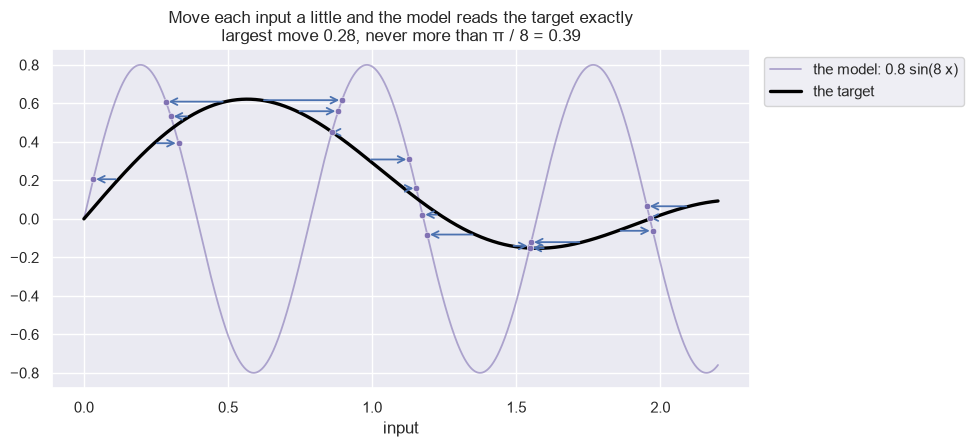

In [7]:
frequency = 8.0
amplitude, phase = 0.8, 0.0
target = lambda inputs: 0.7 * torch.sin(2.5 * inputs) * torch.cos(0.8 * inputs)

xs = torch.linspace(0.0, 2.2, 3000)
picks = torch.linspace(0.12, 2.1, 17)
warp = get_nearest_hit(amplitude, frequency, phase, picks, target(picks))
largest_move = float((warp - picks).abs().max())
report("no arrow is longer than pi / 8", largest_move <= math.pi / 8 + 1e-9, f"largest move {largest_move:.3f}")

figure, axis = plt.subplots(figsize=(9, 4.4))
sns.lineplot(x=xs.numpy(), y=evaluate_sine(amplitude, frequency, phase, xs).numpy(), color=MODEL, alpha=0.6,
             linewidth=1.3, label="the model: 0.8 sin(8 x)", ax=axis)
sns.lineplot(x=xs.numpy(), y=target(xs).numpy(), color=DATA, linewidth=2.4, label="the target", ax=axis)
for pick, moved, height in zip(picks.tolist(), warp.tolist(), target(picks).tolist()):
    axis.annotate("", xy=(moved, height), xytext=(pick, height),
                  arrowprops={"arrowstyle": "->", "color": NEAREST, "linewidth": 1.3})
sns.scatterplot(x=warp.numpy(), y=target(picks).numpy(), color=MODEL, s=22, zorder=4, ax=axis, legend=False)
axis.set_title(f"Move each input a little and the model reads the target exactly{chr(10)}"
               f"largest move {largest_move:.2f}, never more than π / 8 = {math.pi / 8:.2f}")
axis.set_xlabel("input")
axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save_figure(figure, "04-the-warp")

## Figure: before and after the warp

Written to `book/figures/04-before-and-after-warp.png`, from the frequency 2, 8 and 20 warps
measured above. Left: the mean gap between model and target before the warp, and the largest gap
after it (log scale, floored at 1e-16). Right: the largest move of an input against the bound
`pi / frequency`.

wrote book/figures/04-before-and-after-warp.png


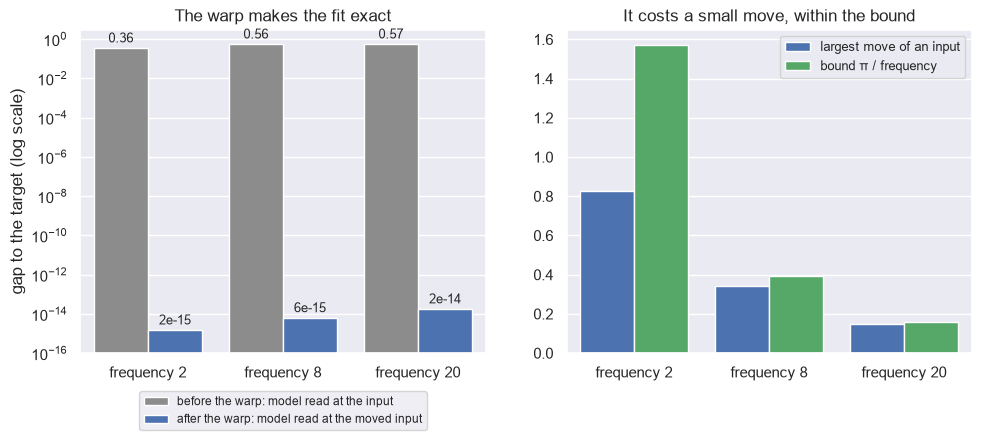

In [8]:
gaps = pd.DataFrame(
    [{"frequency": f"frequency {row['frequency']:g}", "when": "before the warp: model read at the input",
      "gap": row["gap_before"]} for row in warp_rows] +
    [{"frequency": f"frequency {row['frequency']:g}", "when": "after the warp: model read at the moved input",
      "gap": max(row["fit_error"], 1e-16)} for row in warp_rows])
moves = pd.DataFrame(
    [{"frequency": f"frequency {row['frequency']:g}", "what": "largest move of an input",
      "move": row["largest_shift"]} for row in warp_rows] +
    [{"frequency": f"frequency {row['frequency']:g}", "what": "bound π / frequency",
      "move": row["pi_over_frequency"]} for row in warp_rows])

figure, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.barplot(data=gaps, x="frequency", y="gap", hue="when", palette=[BEFORE, NEAREST], errorbar=None, saturation=1, ax=left)
left.set_yscale("log")
left.set_ylim(1e-16, 3)
for container, fmt in zip(left.containers, ("{:.2f}", "{:.0e}")):
    left.bar_label(container, labels=[fmt.format(value) for value in container.datavalues], padding=2, fontsize=9)
left.set_xlabel("")
left.set_ylabel("gap to the target (log scale)")
left.set_title("The warp makes the fit exact")
left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8.5)

sns.barplot(data=moves, x="frequency", y="move", hue="what", palette=[NEAREST, BOUND], errorbar=None, saturation=1, ax=right)
right.set_xlabel("")
right.set_ylabel("")
right.set_title("It costs a small move, within the bound")
right.legend(loc="upper right", fontsize=9)
save_figure(figure, "04-before-and-after-warp")